# Five Regression Python Modules That Every Data Scientist Must Know
This notebook compares the 5 fundamental regression modules across Python's scientific stack:
1. **NumPy** (`np.polyfit` / `np.poly1d`) - Quick polynomial/linear fitting without extra dependencies.
2. **SciPy** (`scipy.stats.linregress`) - Statistical hypothesis testing ($p$-values, standard errors, Pearson $r$).
3. **statsmodels** (`sm.OLS`) - In-depth statistical and econometric regression tables ($t$-scores, $F$-statistic, confidence intervals).
4. **scikit-learn** (`LinearRegression`) - Standard machine learning API focused on predictive modeling and multi-feature pipelines.
5. **Seaborn** (`sns.regplot` / `sns.lmplot`) - High-level visualization combining scatter plots, fit lines, and bootstrap confidence intervals.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# SciPy
import scipy.stats as stats

# statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf

# scikit-learn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

print("All libraries imported successfully.")

All libraries imported successfully.


## 0. The Dataset: GDP per Capita vs. Life Satisfaction
We use the dataset from the article comparing:
* **$x$ (Predictor / Independent variable):** GDP per capita in USD.
* **$y$ (Target / Dependent variable):** Life satisfaction score (0–10 scale).

In [3]:
# GDP per capita (USD)
x = np.array([
    56755.72, 44178.05, 40991.81,  8814.00, 43585.51, 13574.17,  6175.88, 17829.70,
    53254.86, 17522.23, 42784.70, 36638.18, 41086.73, 18167.77, 12706.89, 52564.43,
    61995.42, 35776.80, 30230.23, 34524.47, 13774.61, 14258.23, 101376.50,  9616.65,
    45175.23, 38616.00, 74355.52, 12578.50, 19242.37, 16310.99, 20881.77,  5734.63,
    25732.02, 51545.48, 82081.60, 11006.25, 44974.83, 56839.38
])

# Life satisfaction score (0 - 10)
y = np.array([
    7.3, 7.1, 6.9, 6.4, 7.4, 6.5, 6.3, 6.7,
    7.6, 5.7, 7.6, 6.5, 7.0, 5.4, 5.6, 7.5,
    7.0, 5.9, 7.5, 6.9, 6.9, 6.5, 7.4, 7.3,
    7.6, 6.1, 5.4, 6.2, 5.9, 4.7, 6.3, 7.3,
    7.5, 5.5, 6.8, 6.9, 7.2, 7.3
])

df = pd.DataFrame({"GDP_per_capita": x, "Life_Satisfaction": y})
print(f"Dataset initialized with {len(df)} samples.")
df.head()

Dataset initialized with 38 samples.


,GDP_per_capita,Life_Satisfaction
0,56755.72,7.3
1,44178.05,7.1
2,40991.81,6.9
3,8814.00,6.4
4,43585.51,7.4


## 1. NumPy: `np.polyfit()` & `np.poly1d()`
* **Primary use:** Fast, low-overhead polynomial and linear curve fitting.
* **Mechanism:** Least squares minimization with degree `deg=1`.
* **Limitation:** Does not directly compute standard errors, $p$-values, or handle multi-variable inputs with feature interactions.

--- NumPy polyfit Results ---
Slope (b)     : 9.50823006e-06
Intercept (a) : 6.3451
Fitted Model  :
 
9.508e-06 x + 6.345


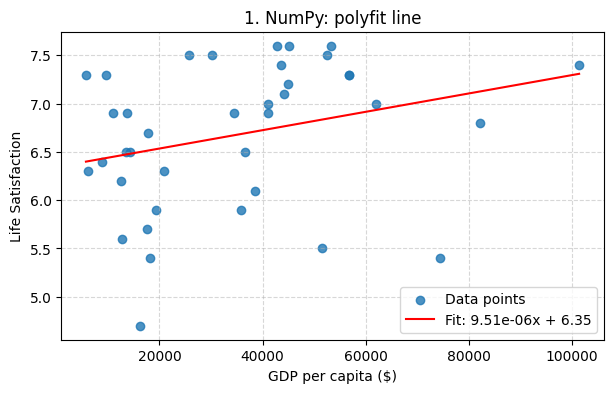

In [4]:
# deg=1 computes slope and intercept: y = b*x + a
coefficients = np.polyfit(x, y, deg=1)
slope_np, intercept_np = coefficients[0], coefficients[1]

# Convert coefficients into a callable polynomial function
p = np.poly1d(coefficients)

print("--- NumPy polyfit Results ---")
print(f"Slope (b)     : {slope_np:.8e}")
print(f"Intercept (a) : {intercept_np:.4f}")
print(f"Fitted Model  :\n{p}")

# Quick visualization
plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="#1f77b4", label="Data points", alpha=0.8)
x_vals = np.linspace(x.min(), x.max(), 200)
plt.plot(x_vals, p(x_vals), color="red", label=f"Fit: {slope_np:.2e}x + {intercept_np:.2f}")
plt.title("1. NumPy: polyfit line")
plt.xlabel("GDP per capita ($)")
plt.ylabel("Life Satisfaction")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 2. SciPy: `scipy.stats.linregress()`
* **Primary use:** Basic linear regression where statistical parameters are needed.
* **Returns:** `LinregressResult` containing:
  * `slope` ($b$) and `intercept` ($a$)
  * `rvalue` (Pearson correlation coefficient $r$)
  * `pvalue` (two-sided $p$-value for hypothesis testing $H_0: \text{slope} = 0$)
  * `stderr` (standard error of the estimated slope)
  * `intercept_stderr` (standard error of the estimated intercept)
* **Limitation:** Only supports simple bivariate linear regression (1 feature).

In [5]:
reg_scipy = stats.linregress(x, y)

print("--- SciPy linregress Results ---")
print(f"Slope            : {reg_scipy.slope:.8e}")
print(f"Intercept        : {reg_scipy.intercept:.4f}")
print(f"Pearson r        : {reg_scipy.rvalue:.4f}")
print(f"R² (rvalue^2)    : {reg_scipy.rvalue**2:.4f}")
print(f"p-value          : {reg_scipy.pvalue:.4e}")
print(f"Slope Std Error  : {reg_scipy.stderr:.4e}")
print(f"Intercept Std Err: {reg_scipy.intercept_stderr:.4f}")

--- SciPy linregress Results ---
Slope            : 9.50823006e-06
Intercept        : 6.3451
Pearson r        : 0.2863
R² (rvalue^2)    : 0.0819
p-value          : 8.1457e-02
Slope Std Error  : 5.3044e-06
Intercept Std Err: 0.2183


## 3. statsmodels: `sm.OLS()`
* **Primary use:** Rigorous statistical and econometric modeling.
* **Key Requirement:** Unlike scikit-learn, `statsmodels.OLS` requires adding the intercept constant explicitly via `sm.add_constant()`.
* **Output:** Full academic regression summary table (R-squared, Adjusted R-squared, F-statistic, t-statistics, p-values, 95% confidence intervals, AIC/BIC).

In [6]:
# Add column of 1s for intercept term
X_sm = sm.add_constant(x)

# Fit Ordinary Least Squares
model_sm = sm.OLS(y, X_sm)
results_sm = model_sm.fit()

# Summary table
print(results_sm.summary())

print("\n--- Extracted Model Parameters ---")
print(f"Intercept (const) : {results_sm.params[0]:.4f}")
print(f"Slope (x1)        : {results_sm.params[1]:.8e}")
print(f"R-squared         : {results_sm.rsquared:.4f}")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.082
Model:                            OLS   Adj. R-squared:                  0.056
Method:                 Least Squares   F-statistic:                     3.213
Date:                Mon, 12 Oct 2026   Prob (F-statistic):             0.0815
Time:                        19:23:41   Log-Likelihood:                -40.985
No. Observations:                  38   AIC:                             85.97
Df Residuals:                      36   BIC:                             89.25
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.3451      0.218     29.062      0.0

## 4. scikit-learn: `sklearn.linear_model.LinearRegression`
* **Primary use:** Production machine learning workflows, pipelining, and predictive inference.
* **Key Format Requirement:** Feature matrix `X` must be 2D (`shape = (n_samples, n_features)`).
* **Strength:** Directly integrates with cross-validation, feature scalers, train-test splitting, and new sample inference via `.predict()`.

In [7]:
X_sklearn = x.reshape(-1, 1)

# Initialize & fit
model_sklearn = LinearRegression(fit_intercept=True)
model_sklearn.fit(X_sklearn, y)

# Retrieve coefficients
slope_skl = model_sklearn.coef_[0]
intercept_skl = model_sklearn.intercept_
r2_skl = model_sklearn.score(X_sklearn, y)

print("--- scikit-learn Results ---")
print(f"Slope (coef_)     : {slope_skl:.8e}")
print(f"Intercept         : {intercept_skl:.4f}")
print(f"R² Score          : {r2_skl:.4f}")

# Predict on new unseen inputs
new_gdp = np.array([[25000], [50000], [75000]])
predicted_scores = model_sklearn.predict(new_gdp)

print("\n--- Predictions on New GDP Inputs ---")
for gdp_val, pred in zip(new_gdp.flatten(), predicted_scores):
    print(f"GDP: ${gdp_val:,.2f}  -->  Predicted Life Satisfaction: {pred:.2f} / 10")

--- scikit-learn Results ---
Slope (coef_)     : 9.50823006e-06
Intercept         : 6.3451
R² Score          : 0.0819

--- Predictions on New GDP Inputs ---
GDP: $25,000.00  -->  Predicted Life Satisfaction: 6.58 / 10
GDP: $50,000.00  -->  Predicted Life Satisfaction: 6.82 / 10
GDP: $75,000.00  -->  Predicted Life Satisfaction: 7.06 / 10


## 5. Seaborn: `sns.regplot()`
* **Primary use:** Instant statistical visualization without manually calculating slope, intercept, or fit lines.
* **Feature:** Plots data points, the fitted line, and a translucent 95% bootstrap confidence interval band for the regression line.

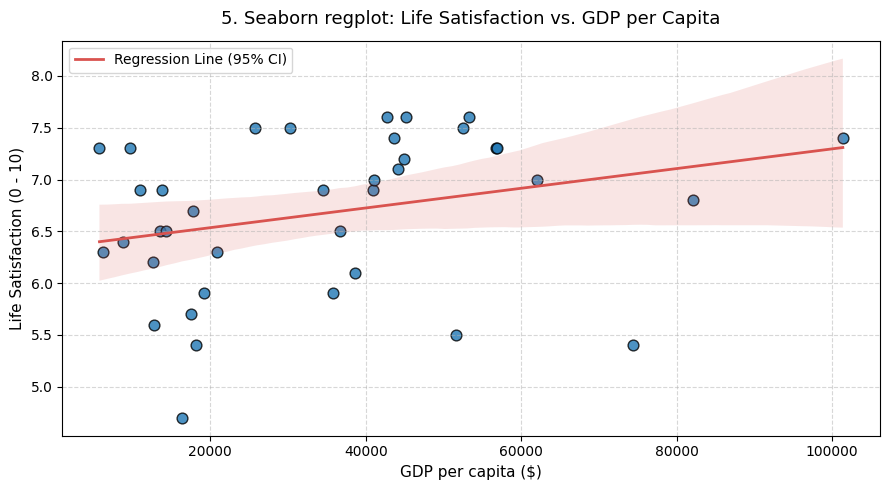

In [8]:
plt.figure(figsize=(9, 5))
sns.regplot(
    x="GDP_per_capita",
    y="Life_Satisfaction",
    data=df,
    ci=95,
    scatter_kws={"color": "#1f77b4", "alpha": 0.8, "s": 60, "edgecolor": "black"},
    line_kws={"color": "#d9534f", "linewidth": 2, "label": "Regression Line (95% CI)"}
)

plt.title("5. Seaborn regplot: Life Satisfaction vs. GDP per Capita", fontsize=13, pad=12)
plt.xlabel("GDP per capita ($)", fontsize=11)
plt.ylabel("Life Satisfaction (0 - 10)", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Summary Comparison Table

| Module / Library | Primary Target | Strengths | Main Limitations |
| :--- | :--- | :--- | :--- |
| **NumPy (`polyfit`)** | Basic Math & Curve Fitting | Fast, zero extra dependencies, native polynomial support | No $p$-values, confidence intervals, or multivariate regression |
| **SciPy (`linregress`)** | Hypothesis Testing | Provides slope, intercept, $p$-value, stderr, and $r$ in one call | Only bivariate (1 feature), no ML `.predict()` method |
| **statsmodels (`OLS`)** | Econometrics & Research | Complete statistical reports ($t$-scores, $F$-stat, $R^2$, AIC/BIC) | Requires manual `add_constant()`, more verbose syntax |
| **scikit-learn (`LinearRegression`)** | Machine Learning Pipelines | Standardized API (`fit`, `predict`, `score`), multi-feature scaling | No statistical significance outputs ($p$-values or standard errors) |
| **Seaborn (`regplot`)** | Visual Analytics | Generates scatter, regression fit, and 95% CI bands in a single line | Visualization only; does not expose learned numerical coefficients |